# Savitsky current-hull calculation workbook

Reproduce the **October 21, 2026** run, inspect each calculation, and try changes. The Python equations and equilibrium solver are visible below; JavaScript, Node and OpenPlaning are not runtime dependencies.

**Start:** select a Python kernel with `pandas`, `matplotlib`, and `ipykernel`, then **Run All**. For a fresh environment: `python -m pip install -r optimization/savitsky/requirements-notebook.txt`. Launch with `jupyter lab optimization/savitsky/current-hull.ipynb` (install JupyterLab if needed), or open this file in VS Code's notebook editor.

**Iterate:** edit `OVERRIDES` and `SPEEDS_MPH` in section 2, then run that cell and all cells below it. For persistent defaults edit [current-hull-inputs.json](current-hull-inputs.json), then Run All. Section 9 compares several designs without changing the reference. Section 10 optionally exports a new run. Committed outputs show the default configuration.

**Scope:** calm-water equivalent prismatic V-bottom; no low-speed displacement model, waves, appendage/air drag, porpoising or propulsion efficiency. Effective power is horizontal resistance × speed, not shaft or battery power. Every original solved speed wets beyond the assumed uniform aft 38 inches. Numerical agreement does not validate the actual hull or establish planing onset/top speed.

Equations are ported from [model.js](model.js), adapted from OpenPlaning under the [MIT notice](NOTICE.txt). The original engine also supports 1976 geometry and flaps; this workbook deliberately rejects those options to keep the calculation for this run explicit. [Original report](../../outputs/savitsky/current-hull-2026-10-21/RESULTS.md).


## Savitsky model

This reference summarizes the **1964 wetted-geometry, no-flap model implemented below**, including ITTC friction, the optional roughness allowance, and thrust-line moments. It describes the notebook's complete calm-water calculation; the lift and pressure-center relations are Savitsky's empirical component. [Equation source and attribution](NOTICE.txt); [original run](../../outputs/savitsky/current-hull-2026-10-21/RESULTS.md).

**Notation and units.** $V$ is speed (m/s); $b$ is chine beam (m); $m$ is loaded mass (kg); $\rho$ is water density (kg/m³); $\nu$ is kinematic viscosity (m²/s); $k$ is roughness (m); $g=9.8066\;\mathrm{m/s^2}$. The unknowns are 
- trim $\tau$ wetted length 
- keel wetted length $L_K$ (m). 
- Deadrise is $\beta$, relative to the keel 
- thrust angle relative to the keel is $\epsilon$. 

Trigonometric arguments use radians. **The empirical factors $\tau_{\deg}$ and $\beta_{\deg}$ use numerical angles in degrees.** Positions $(x_g,z_g)$ denote the CG and $(x_T,z_T)$ a point on the thrust line, measured forward from the transom and upward from the keel.

**1. Wetted geometry and speed coefficient**

$$
\begin{aligned}
\Delta L_{\rm raw} &= \frac{b}{\pi}\frac{\tan\beta}{\tan\tau}, &
L_C &= \max(0,L_K-\Delta L_{\rm raw}),\\
\lambda &= \frac{L_K+L_C}{2b}, &
C_v &= \frac{V}{\sqrt{gb}},\\
\alpha &= \operatorname{atan2}(b,2\Delta L_{\rm raw}), &
\Delta L &= \begin{cases}\Delta L_{\rm raw}, & L_K\geq\Delta L_{\rm raw},\\ L_K, & L_K<\Delta L_{\rm raw},\end{cases}\\
S_1 &= \frac{\Delta L^2\tan\alpha}{\cos\beta}, &
S_2 &= \frac{bL_C}{\cos\beta},\qquad S=S_1+S_2.
\end{aligned}
$$

$L_C$ is chine wetting, $\lambda$ is mean wetting divided by beam, $\alpha$ is the spray-line angle, and $S$ is wetted area. The spray-line angle is evaluated before the dry-chine clamp, as in the original engine.

**2. Lift, pressure resistance, and pressure center**

$$
\begin{aligned}
C_{L0} &= \tau_{\deg}^{1.1}\left(0.012\sqrt{\lambda}+\frac{0.0055\lambda^{5/2}}{C_v^2}\right),\\
C_{L\beta} &= C_{L0}-0.0065\beta_{\deg}C_{L0}^{0.6},\\
L &= \tfrac12\rho V^2b^2 C_{L\beta},\qquad
N=\frac{L}{\cos\tau},\qquad D_p=L\tan\tau,\\
x_p &= \lambda b\left(0.75-\frac{1}{5.21(C_v/\lambda)^2+2.39}\right).
\end{aligned}
$$

$L$ is vertical hydrodynamic lift, $N$ is bottom-normal force, $D_p$ is horizontal pressure resistance, and $x_p$ is the pressure center forward of the transom.

**3. Bottom flow, friction, and friction moment arm**

$$
\begin{aligned}
B &= 0.012\tau_{\deg}^{1.1}\sqrt{\lambda},\\
f_v &= 1-\frac{B-0.0065\beta_{\deg}B^{0.6}}{\lambda\cos\tau},\qquad
Re=\frac{V\sqrt{f_v}\lambda b}{\nu},\\
C_f &= \frac{0.075}{(\log_{10}Re-2)^2},\\
\Delta C_f &= \begin{cases}
0,&k=0,\\
\displaystyle\frac{44\left[(k/(\lambda b))^{1/3}-10Re^{-1/3}\right]+0.125}{1000},&k>0,
\end{cases}\\
F_f &= \tfrac12\rho V^2(C_f+\Delta C_f)S,\\
z_f &= \frac{(b/4)\tan\beta\,S_2+(b/6)\tan\beta\,S_1}{S}.
\end{aligned}
$$

$f_v$ is the squared bottom-flow/free-stream speed ratio. The corrected speed enters $Re$; the friction force uses $V^2$, matching the saved model. $F_f$ acts along the bottom, and $z_f$ is its effective height above the keel.

**4. Resistance, combined shaft thrust, and effective power**

$$
\begin{aligned}
R &= D_p+F_f\cos\tau, &
T &= \frac{R}{\cos(\tau+\epsilon)},\\
P_E &= \frac{RV}{1000}\;\mathrm{kW}, &
T_{\rm per\ prop} &= \frac{T}{n_{\rm prop}}.
\end{aligned}
$$

$R$ is horizontal resistance, $T$ is total thrust along the shafts, and $n_{\rm prop}$ is propeller count with equal sharing assumed. $P_E$ excludes propulsion losses.

**5. Coupled equilibrium: solve for $\tau$ and $L_K$ at each $V$**

$$
\boxed{F_z(\tau,L_K)=L-F_f\sin\tau-mg+T\sin(\tau+\epsilon)=0}
$$

$$
\begin{aligned}
M_p &= -N(x_g-x_p),\\
M_f &= F_f(z_f-z_g),\\
M_T &= T\left[\cos\epsilon(z_g-z_T)-\sin\epsilon(x_g-x_T)\right],\\
M(\tau,L_K) &= M_p+M_f+M_T=0.
\end{aligned}
$$

The solver bisects $L_K$ for vertical equilibrium at each trial trim, then brackets and bisects pitch equilibrium over $0.5^\circ\leq\tau\leq35^\circ$. If multiple roots are found, it selects the root closest to $3^\circ$. Accepted residuals satisfy

$$
\frac{|F_z|}{mg}\leq10^{-6},\qquad
\frac{|M|}{mgL_{\rm hull}}\leq10^{-6}.
$$

**Applicability in this workbook.** No moving solution is evaluated for $C_v<1$. Implemented screens flag trim outside $2^\circ$–$15^\circ$, $\lambda>4$, $C_v>13$, wetting beyond hull length, dry chines, high deadrise, and nonphysical drag. Wetting beyond the assumed uniform aft section is reported separately. These are numerical and empirical checks, not proof of planing or stability. The sections below expose the same equations in Python and substitute the selected inputs.



## Decision tree: increase or decrease a design variable

![Chine beam decision tree](../../hull/diagrams/beam-decision-tree.png)

[Decision tree and equation-by-equation branches](../../hull/diagrams/decision-tree.md) · [All-variable increase/decrease results](../../hull/diagrams/decision-sensitivities.md) · [Overall system flow](../../hull/diagrams/variable-flow.md)

Follow a decision through the equations at fixed trim and wetted keel length first, then through the equilibrium re-solve. For beam, increasing b raises ΔL but lowers λb at fixed attitude, so Reynolds number need not increase. The diagram includes both wider and narrower cases at 22 mph.


In [3]:
from pathlib import Path
import copy
import hashlib
import json
import math
import platform
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works when launched from this folder, optimization/, or the repository root.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'optimization/savitsky/current-hull-inputs.json').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Open the notebook from within the hav repository.')
INPUT_FILE = ROOT / 'optimization/savitsky/current-hull-inputs.json'
config = json.loads(INPUT_FILE.read_text())
REFERENCE_FILE = ROOT / config['reference_file']
reference = json.loads(REFERENCE_FILE.read_text())
G = 9.8066                 # m/s²; retained from the original engine
MPH_TO_M_S = 0.44704       # exact
IN_TO_M = 0.0254           # exact
N_PER_LBF = 4.4482216152605
print('Python', platform.python_version())
print('Inputs:', INPUT_FILE.relative_to(ROOT))
print('Reference:', REFERENCE_FILE.relative_to(ROOT))
print('Reference SHA-256:', hashlib.sha256(REFERENCE_FILE.read_bytes()).hexdigest())


Python 3.13.16
Inputs: optimization/savitsky/current-hull-inputs.json
Reference: outputs/savitsky/current-hull-2026-10-21/results.json
Reference SHA-256: a17f128d328b52b5882c759357711431027de6c5b3351781557b81c9a724505c


## 1. Input data and provenance

Values below retain the saved run's precision. The imperial descriptions in the report are rounded; the SI values are the actual inputs. Positions use +x forward from the transom and +z above the aft keel. The thrust point may be aft/below this origin. Its signed coordinates enter the moment equation; distance from the CG alone is insufficient.

These are copied inputs and assumptions, not a fresh measurement from CAD. The historical JSON is retained unchanged for regression checks.


In [4]:
def input_table(params):
    return pd.DataFrame([
        {'input': k, 'value': v, **config['input_notes'][k]}
        for k, v in params.items()
    ]).set_index('input')

display(input_table(config['inputs']))
for assumption in config['assumptions']:
    print('•', assumption)


,value,unit,meaning
input,,,
length_m,1.828800,m,Overall length; 72 in
beam_m,0.304800,m,Chine beam; 12 in
mass_kg,56.811991,kg,Total loaded mass; recorded as 125.249 lb
deadrise_deg,13.161188,deg,Equivalent V: degrees(atan(1.403 / 6)); curved...
lcg_m,0.598094,m,CG forward of transom; 23.547 in
vcg_m,0.154407,m,CG above aft keel datum; 6.079 in
thrust_height_m,-0.032824,m,"Point on shaft line, above keel; negative = be..."
thrust_x_m,-0.122527,m,"Point on shaft line, forward of transom; negat..."
thrust_angle_deg,15.000000,deg,Upward forward thrust angle relative to keel


• Equivalent constant V-bottom: atan(1.403/6) = 13.161 degrees; curved section with 5-degree keel slope is not represented exactly.
• Aft 38 inches assumed uniform; all solved points predict wetting beyond this section. No clipping of predicted wetting.
• Freshwater 20 C, density 998.2 kg/m3, viscosity 1.004e-6 m2/s.
• Smooth hull: roughness allowance zero. Fully turbulent ITTC friction; actual finish unknown.
• No displacement/wave-making resistance, appendage drag, air drag, propeller interaction, waves or dynamic stability model.
• Total thrust is along both shafts combined. Per-prop figures assume equal thrust. Effective power is horizontal resistance times speed, not motor shaft or battery power.
• CAD +Y forward, +Z up; aft keel assumed parallel to top plane; transverse CG offset 0.004 in ignored in symmetric calculation.
• Cv<1 cutoff is not a prediction of planing onset.


## 2. Edit a design and speed grid

SI units unless a name ends in `_deg`. Examples: `{"mass_kg": 60.0, "lcg_m": 0.62}`. Set `DETAIL_MPH` to inspect one speed in section 7. `UNIFORM_AFT_LENGTH_M` is a geometry warning threshold, not a cap on predicted wetted length. Changing it does not change the forces. Per-prop thrust assumes equal sharing.


In [5]:
OVERRIDES = {}  # e.g. {"mass_kg": 60.0, "lcg_m": 0.62}
SPEEDS_MPH = list(range(31))
DETAIL_MPH = 22.0
UNIFORM_AFT_LENGTH_M = config['uniform_aft_length_m']
PROPELLER_COUNT = config['propeller_count']

params = {**config['inputs'], **OVERRIDES}
display(input_table(params))

,value,unit,meaning
input,,,
length_m,1.828800,m,Overall length; 72 in
beam_m,0.304800,m,Chine beam; 12 in
mass_kg,56.811991,kg,Total loaded mass; recorded as 125.249 lb
deadrise_deg,13.161188,deg,Equivalent V: degrees(atan(1.403 / 6)); curved...
lcg_m,0.598094,m,CG forward of transom; 23.547 in
vcg_m,0.154407,m,CG above aft keel datum; 6.079 in
thrust_height_m,-0.032824,m,"Point on shaft line, above keel; negative = be..."
thrust_x_m,-0.122527,m,"Point on shaft line, forward of transom; negat..."
thrust_angle_deg,15.000000,deg,Upward forward thrust angle relative to keel


## 3. Wetted geometry and lift

At a trial speed $V$, trim $\tau$ and keel wetting $L_K$, use beam $b$ and deadrise $\beta$. Trigonometry uses radians, but the empirical powers of $\tau$ and coefficients multiplying $\beta$ use **degrees**.

$$\Delta L=\frac{b}{\pi}\frac{\tan\beta}{\tan\tau},\quad L_C=\max(0,L_K-\Delta L),\quad \lambda=\frac{L_K+L_C}{2b},\quad C_v=\frac{V}{\sqrt{gb}}$$
$$C_{L0}=\tau_{deg}^{1.1}\left(0.012\sqrt\lambda+\frac{0.0055\lambda^{2.5}}{C_v^2}\right),\quad C_{L\beta}=C_{L0}-0.0065\beta_{deg}C_{L0}^{0.6}$$
$$L=C_{L\beta}\frac{\rho V^2 b^2}{2},\quad N=L/\cos\tau,\quad D_p=L\tan\tau$$
$$x_p=\lambda b\left(0.75-\frac{1}{5.21(C_v/\lambda)^2+2.39}\right)$$

The spray-line angle is calculated before the dry-chine clamp, matching the original engine. For dry chines, use $\Delta L=L_K$ in the area calculation. This branch is flagged as less reliable.
$$\alpha=\operatorname{atan2}(b,2\Delta L_{raw}),\quad S_1=\Delta L^2\tan\alpha/\cos\beta,\quad S_2=b L_C/\cos\beta,\quad S=S_1+S_2$$

$
C_{L0} \text{ holds for } 0.60 \le C_v \le 13.00, \ 2^{\circ} \le \tau \le 15^{\circ}, \ \lambda \le 4
$


In [6]:
def validate(p):
    expected = set(config['inputs'])
    if set(p) != expected:
        raise ValueError(f'Input keys differ: {set(p) ^ expected}')
    if not all(isinstance(v, (int, float)) and math.isfinite(v) for v in p.values()):
        raise ValueError('All inputs must be finite numbers.')
    for k in ['length_m', 'beam_m', 'mass_kg', 'lcg_m', 'density_kg_m3', 'viscosity_m2_s']:
        if p[k] <= 0:
            raise ValueError(f'{k} must be positive.')
    if p['beam_m'] > p['length_m'] or p['lcg_m'] >= p['length_m']:
        raise ValueError('Beam and LCG must fit within hull length.')
    if not 0 <= p['deadrise_deg'] <= 45 or abs(p['thrust_angle_deg']) > 20:
        raise ValueError('Supported deadrise: 0–45°; thrust angle: ±20°.')
    if p['vcg_m'] < 0 or p['roughness_m'] < 0:
        raise ValueError('VCG and roughness must be nonnegative.')
    if p['wetted_lengths_type'] != 2 or any(p[k] != 0 for k in
            ['flap_chord_m', 'flap_span_ratio', 'flap_angle_deg']):
        raise ValueError('This workbook supports only 1964 geometry and no flap.')


def geometry_and_lift(p, speed, trim_deg, keel_m):
    b, beta = p['beam_m'], p['deadrise_deg']
    tau, beta_rad = math.radians(trim_deg), math.radians(beta)
    gap_raw = b / math.pi * math.tan(beta_rad) / math.tan(tau)
    chine_raw = keel_m - gap_raw
    chine = max(0.0, chine_raw)
    lam = (keel_m + chine) / (2 * b)
    alpha = math.atan2(b, 2 * gap_raw)
    gap = keel_m if chine_raw < 0 else gap_raw
    cv = speed / math.sqrt(G * b)
    cl0 = trim_deg**1.1 * (0.012 * math.sqrt(lam) + 0.0055 * lam**2.5 / cv**2)
    cl_beta = cl0 - 0.0065 * beta * cl0**0.6
    lift = cl_beta * 0.5 * p['density_kg_m3'] * speed**2 * b**2
    cp = lam * b * (0.75 - 1 / (5.21 * (cv / lam)**2 + 2.39))
    s1 = gap**2 * math.tan(alpha) / math.cos(beta_rad)
    s2 = b * chine / math.cos(beta_rad)
    return dict(trim_deg=trim_deg, keel_wetted_m=keel_m, chine_wetted_m=chine,
                lambda_=lam, cv=cv, gap_raw_m=gap_raw, gap_m=gap,
                spray_angle_deg=math.degrees(alpha), area_triangle_m2=s1,
                area_rectangle_m2=s2, wetted_area_m2=s1+s2,
                cl_zero_deadrise=cl0, cl_deadrise=cl_beta, lift_n=lift,
                normal_force_n=lift / math.cos(tau), center_pressure_m=cp,
                pressure_drag_n=lift * math.tan(tau),
                transom_draft_m=keel_m * math.sin(tau))


## 4. Friction, thrust, and equilibrium equations

The bottom-flow correction determines Reynolds number. Friction uses the original engine's $V^2$, with the corrected flow speed used in $Re$:



$$
\begin{aligned}
B&=0.012\tau_{deg}^{1.1}\sqrt\lambda,\quad \\

f_v&=1-\frac{B-0.0065\beta_{deg}B^{0.6}}{\lambda\cos\tau},\quad \\

Re&=\frac{V\sqrt{f_v}\lambda b}{\nu} \\

C_f&=\frac{0.075}{(\log_{10}Re-2)^2},\quad \\

\Delta C_f&=\frac{44[(k/(\lambda b))^{1/3}-10 Re^{-1/3}]+0.125}{1000} \\
\end{aligned}
$$

Set $\Delta C_f=0$ when roughness $k=0$. Then $$F_f=\frac12\rho(C_f+\Delta C_f)S V^2$$ Its line of action has height $z_f=[(b/4)\tan\beta\,S_2+(b/6)\tan\beta\,S_1]/S$.

With shaft angle $\epsilon$ relative to keel, weight $W=mg$, CG $(x_g,z_g)$ and thrust point $(x_T,z_T)$:
$$R=D_p+F_f\cos\tau,\quad T=\frac{R}{\cos(\tau+\epsilon)},\quad P_E=RV/1000\;\text{kW}$$
$$F_z=L-F_f\sin\tau-W+T\sin(\tau+\epsilon)=0$$

Even if our vertical forces balance we need to make sure they cannot rotate the boat. We can calculate three of these moments around the center of gravity:

$$
\begin{aligned}
&(1)\quad & M_p &= -N(x_g-x_p), \\
&(2)\quad & M_f &= F_f(z_f-z_g), \\
&(3)\quad & M_T &= T[\cos\epsilon(z_g-z_T)-\sin\epsilon(x_g-x_T)], \\
&(4)\quad & M &= M_p+M_f+M_T=0
\end{aligned}
$$

The following function exposes **every intermediate quantity**, including signed force and moment terms. All moments are about the CG using the original engine's signs. Total thrust is along the shafts; resistance is horizontal.


In [7]:
def forces(p, speed, trim_deg, keel_m):
    r = geometry_and_lift(p, speed, trim_deg, keel_m)
    b, beta = p['beam_m'], p['deadrise_deg']
    tau, eps = math.radians(trim_deg), math.radians(p['thrust_angle_deg'])
    lam = r['lambda_']
    base = 0.012 * trim_deg**1.1 * math.sqrt(lam)
    vm2 = 1 - (base - 0.0065 * beta * base**0.6) / (lam * math.cos(tau))
    if vm2 <= 0 or r['wetted_area_m2'] <= 0:
        raise ValueError('No physical bottom-flow estimate.')
    re = speed * math.sqrt(vm2) * lam * b / p['viscosity_m2_s']
    if re <= 100:
        raise ValueError('Reynolds number outside friction model.')
    cf = 0.075 / (math.log10(re) - 2)**2
    dcf = ((44 * ((p['roughness_m'] / (lam*b))**(1/3) - 10*re**(-1/3)) + 0.125)
           / 1000) if p['roughness_m'] > 0 else 0.0
    friction = 0.5 * p['density_kg_m3'] * (cf+dcf) * r['wetted_area_m2'] * speed**2
    friction_height = ((b/4 * math.tan(math.radians(beta)) * r['area_rectangle_m2']
                       + b/6 * math.tan(math.radians(beta)) * r['area_triangle_m2'])
                       / r['wetted_area_m2'])
    drag = r['pressure_drag_n'] + friction * math.cos(tau)
    thrust = drag / math.cos(tau+eps)
    weight = p['mass_kg'] * G
    friction_vertical = -friction * math.sin(tau)
    thrust_vertical = thrust * math.sin(tau+eps)
    pressure_moment = -r['normal_force_n'] * (p['lcg_m'] - r['center_pressure_m'])
    friction_moment = friction * (friction_height - p['vcg_m'])
    thrust_moment = thrust * (math.cos(eps)*(p['vcg_m']-p['thrust_height_m'])
                             - math.sin(eps)*(p['lcg_m']-p['thrust_x_m']))
    return {**r, 'lambda': lam, 'bottom_flow_speed_ratio_squared': vm2,
            'reynolds_number': re, 'cf_ittc': cf, 'cf_roughness': dcf,
            'friction_coefficient': cf+dcf, 'friction_force_n': friction,
            'friction_height_m': friction_height, 'friction_drag_n': friction*math.cos(tau),
            'flap_drag_n': 0.0, 'resistance_n': drag, 'thrust_n': thrust,
            'effective_power_kw': drag*speed/1000, 'weight_n': weight,
            'friction_vertical_n': friction_vertical, 'thrust_vertical_n': thrust_vertical,
            'pressure_moment_nm': pressure_moment, 'friction_moment_nm': friction_moment,
            'thrust_moment_nm': thrust_moment,
            'vertical_residual_n': r['lift_n']+friction_vertical-weight+thrust_vertical,
            'moment_residual_nm': pressure_moment+friction_moment+thrust_moment}


## 5. Solve trim and wetted length

For each trial trim, bracket and bisect keel length until vertical force balances. Scan 0.5–35° trim at 0.25° intervals, then bisect each pitch-moment sign change. Keep the root closest to 3° and flag multiple roots. This matches the JavaScript solver's search and iteration counts, making comparisons traceable. A sign-change search can miss tangent roots or roots between disconnected valid regions.

No guessed trim replaces a failed solve. `Cv < 1` returns unavailable, not zero drag. At rest only motion resistance/power are zero; static attitude is not solved. Empirical screening checks and the uniform-aft geometry warning are separate columns. Passing a screen does not establish actual-hull validity.


In [8]:
def vertical_balance(p, speed, trim_deg):
    lo, hi = p['beam_m']*1e-5, max(p['length_m'], p['beam_m'])
    a = None
    for _ in range(30):
        try:
            a = forces(p, speed, trim_deg, lo)
            break
        except (ValueError, OverflowError, ZeroDivisionError):
            lo *= 2
    if a is None or lo >= hi:
        return None
    try:
        b = forces(p, speed, trim_deg, hi)
        for _ in range(10):
            if b['vertical_residual_n'] >= 0:
                break
            hi *= 2
            b = forces(p, speed, trim_deg, hi)
        if a['vertical_residual_n'] > 0 or b['vertical_residual_n'] < 0:
            return None
        for _ in range(58):
            mid = (lo+hi)/2
            if forces(p, speed, trim_deg, mid)['vertical_residual_n'] > 0:
                hi = mid
            else:
                lo = mid
        return forces(p, speed, trim_deg, (lo+hi)/2)
    except (ValueError, OverflowError, ZeroDivisionError):
        return None


def solve(p, speed):
    validate(p)
    if not math.isfinite(speed) or speed < 0:
        raise ValueError('Speed must be finite and nonnegative.')
    if speed == 0:
        return dict(speed_m_s=0, status='static', resistance_n=0,
                    effective_power_kw=0, warnings=['Static trim and draft not calculated.'])
    cv = speed/math.sqrt(G*p['beam_m'])
    if cv < 1:
        return dict(speed_m_s=speed, cv=cv, status='displacement_unmodeled',
                    warnings=['No displacement or wave-making resistance model.'])
    roots, prior = [], None
    for i in range(139):
        trim = 0.5+i*0.25
        r = vertical_balance(p, speed, trim)
        if r is not None and prior is not None and r['moment_residual_nm']*prior['moment_residual_nm'] <= 0:
            lo, hi = prior['trim_deg'], trim
            for _ in range(42):
                mid = vertical_balance(p, speed, (lo+hi)/2)
                if mid is None:
                    break
                if mid['moment_residual_nm']*prior['moment_residual_nm'] > 0:
                    lo = mid['trim_deg']
                else:
                    hi = mid['trim_deg']
            root = vertical_balance(p, speed, (lo+hi)/2)
            if root is not None:
                roots.append(root)
        prior = r
    if not roots:
        return dict(speed_m_s=speed, cv=cv, status='no_equilibrium',
                    warnings=['No bracketed equilibrium in 0.5–35° trim search.'])
    r = min(roots, key=lambda item: abs(item['trim_deg']-3))
    warnings = []
    checks = [
        (not 2 <= r['trim_deg'] <= 15, 'Trim outside 2–15 degree empirical range.'),
        (r['lambda'] > 4, 'Mean wetted length / beam exceeds 4.'),
        (cv > 13, 'Beam speed coefficient exceeds 13.'),
        (r['keel_wetted_m'] > p['length_m'], 'Predicted keel wetting exceeds actual hull length.'),
        (r['chine_wetted_m'] == 0, 'Dry chines: simplified geometry may be unreliable.'),
        (p['deadrise_deg'] > 30, 'High deadrise: review applicability.'),
        (min(r['friction_coefficient'], r['resistance_n'], r['thrust_n']) <= 0,
         'Nonphysical resistance prediction.'),
        (len(roots) > 1, 'Multiple equilibria; selected closest to 3° trim.')]
    warnings = [message for flag, message in checks if flag]
    if (abs(r['vertical_residual_n']) > 1e-6*p['mass_kg']*G or
            abs(r['moment_residual_nm']) > 1e-6*p['mass_kg']*G*p['length_m']):
        raise ArithmeticError('Equilibrium residual tolerance not met.')
    return dict(speed_m_s=speed, status='outside_limits' if warnings else 'within_screen',
                **r, warnings=warnings)


def run_sweep(p, speeds_mph, uniform_aft_m, propeller_count):
    if not math.isfinite(uniform_aft_m) or uniform_aft_m <= 0:
        raise ValueError('Uniform aft length must be positive and finite.')
    if not isinstance(propeller_count, int) or propeller_count < 1:
        raise ValueError('Propeller count must be a positive integer.')
    rows = []
    for mph in speeds_mph:
        r = solve(p, mph*MPH_TO_M_S)
        r['speed_mph'] = mph
        r['forebody_approximation'] = r.get('keel_wetted_m', 0) > uniform_aft_m
        r['geometry_warning'] = ('Wetting beyond assumed uniform aft section.'
                                 if r['forebody_approximation'] else '')
        if 'thrust_n' in r:
            r['total_thrust_lbf'] = r['thrust_n']/N_PER_LBF
            r['per_prop_thrust_lbf'] = r['total_thrust_lbf']/propeller_count
            r['keel_wetted_in'] = r['keel_wetted_m']/IN_TO_M
        rows.append(r)
    return rows


## 6. Reproduce the saved run before changing anything

This check always uses the original inputs and original speed grid, independently of `OVERRIDES`. Compare **all saved numeric output fields** at all 31 speeds, plus engine status and the 38-inch geometry flag. Residuals near zero use an absolute tolerance; other values use relative tolerance. The original report appended the forebody warning without changing engine status; this workbook keeps it separate. Matching this run checks the port, not the empirical accuracy of the underlying model.


In [9]:
reference_rows = run_sweep(reference['inputs'],
                           [r['speed_mph'] for r in reference['results']], 38*IN_TO_M, 2)
errors = []
for old, new in zip(reference['results'], reference_rows):
    assert old['status'] == new['status'], (old['speed_mph'], 'status')
    assert new['forebody_approximation'] == any('38 inches' in w for w in old['warnings'])
    for key, value in old.items():
        if isinstance(value, (int, float)):
            actual = new[key]
            assert math.isclose(actual, value, rel_tol=1e-8, abs_tol=1e-9), (old['speed_mph'], key, actual, value)
            errors.append({'field': key, 'absolute_difference': abs(actual-value)})
display(pd.DataFrame(errors).groupby('field').max())
print(f'PASS: {len(reference_rows)} speeds; {len(errors)} numeric comparisons; status and geometry flags match.')


,absolute_difference
field,
center_pressure_m,2.220446e-16
chine_wetted_m,2.220446e-16
cv,0.000000e+00
effective_power_kw,3.330669e-16
flap_drag_n,0.000000e+00
friction_coefficient,8.673617e-19
friction_drag_n,1.421085e-14
keel_wetted_in,7.105427e-15
keel_wetted_m,2.220446e-16


PASS: 31 speeds; 607 numeric comparisons; status and geometry flags match.


## 7. Current design: results and a worked calculation

`audit` below contains the entire calculation at `DETAIL_MPH`. Change that value in section 2 and rerun from there. Missing trim/thrust at low speed means unavailable. The next table displays signed terms in the two balance equations so you can sum them yourself.


In [8]:
rows = run_sweep(params, SPEEDS_MPH, UNIFORM_AFT_LENGTH_M, PROPELLER_COUNT)
results = pd.DataFrame(rows)
columns = ['speed_mph', 'trim_deg', 'total_thrust_lbf', 'per_prop_thrust_lbf',
           'effective_power_kw', 'keel_wetted_in', 'status', 'geometry_warning', 'warnings']
display(results.reindex(columns=columns).round(6))

audit = solve(params, DETAIL_MPH*MPH_TO_M_S)
print(f'Worked speed: {DETAIL_MPH:g} mph = {DETAIL_MPH*MPH_TO_M_S:.8g} m/s')
if 'trim_deg' not in audit:
    print(audit)
else:
    def quantity_unit(key):
        if key.endswith('_nm'): return 'N·m'
        if key.endswith('_n'): return 'N'
        if key.endswith('_m2'): return 'm²'
        if key.endswith('_m_s'): return 'm/s'
        if key.endswith('_m'): return 'm'
        if key.endswith('_deg'): return 'deg'
        if key.endswith('_kw'): return 'kW'
        return '1'
    display(pd.DataFrame([{'quantity': k, 'value': v, 'unit': quantity_unit(k)}
                          for k, v in audit.items() if isinstance(v, (int, float))]).set_index('quantity'))
    display(pd.DataFrame([
        {'balance': 'Vertical force', 'term': 'Lift', 'value': audit['lift_n'], 'unit': 'N'},
        {'balance': 'Vertical force', 'term': 'Friction vertical', 'value': audit['friction_vertical_n'], 'unit': 'N'},
        {'balance': 'Vertical force', 'term': 'Weight (down)', 'value': -audit['weight_n'], 'unit': 'N'},
        {'balance': 'Vertical force', 'term': 'Thrust vertical', 'value': audit['thrust_vertical_n'], 'unit': 'N'},
        *[{'balance': 'Pitch moment', 'term': k, 'value': audit[k], 'unit': 'N·m'}
          for k in ['pressure_moment_nm', 'friction_moment_nm', 'thrust_moment_nm']]
    ]))
    print('Residuals:', audit['vertical_residual_n'], 'N;', audit['moment_residual_nm'], 'N·m')
    print('Engine screen:', audit['status'], audit['warnings'])
    print('Forebody approximation:', audit['keel_wetted_m'] > UNIFORM_AFT_LENGTH_M)


,speed_mph,trim_deg,total_thrust_lbf,per_prop_thrust_lbf,effective_power_kw,keel_wetted_in,status,geometry_warning,warnings
0,0,NaN,NaN,NaN,0.000000,NaN,static,,[Static trim and draft not calculated.]
1,1,NaN,NaN,NaN,NaN,NaN,displacement_unmodeled,,[No displacement or wave-making resistance mod...
2,2,NaN,NaN,NaN,NaN,NaN,displacement_unmodeled,,[No displacement or wave-making resistance mod...
3,3,NaN,NaN,NaN,NaN,NaN,displacement_unmodeled,,[No displacement or wave-making resistance mod...
4,4,7.946554,18.652166,9.326083,0.136622,68.388505,outside_limits,Wetting beyond assumed uniform aft section.,[Mean wetted length / beam exceeds 4.]
5,5,8.563989,20.350910,10.175455,0.185470,64.818161,outside_limits,Wetting beyond assumed uniform aft section.,[Mean wetted length / beam exceeds 4.]
6,6,9.314462,22.361019,11.180509,0.243129,60.605934,outside_limits,Wetting beyond assumed uniform aft section.,[Mean wetted length / beam exceeds 4.]
7,7,10.124272,24.500076,12.250038,0.308769,56.046403,outside_limits,Wetting beyond assumed uniform aft section.,[Mean wetted length / beam exceeds 4.]
8,8,10.827710,26.393243,13.196622,0.377929,51.632221,outside_limits,Wetting beyond assumed uniform aft section.,[Mean wetted length / beam exceeds 4.]
9,9,11.235321,27.630274,13.815137,0.443554,47.860990,within_screen,Wetting beyond assumed uniform aft section.,[]


Worked speed: 22 mph = 9.83488 m/s


,value,unit
quantity,,
speed_m_s,9.834880e+00,m/s
trim_deg,5.426987e+00,deg
keel_wetted_m,9.811241e-01,m
chine_wetted_m,7.423244e-01,m
lambda_,2.827179e+00,1
cv,5.688560e+00,1
gap_raw_m,2.387997e-01,m
gap_m,2.387997e-01,m
spray_angle_deg,3.254568e+01,deg


,balance,term,value,unit
0,Vertical force,Lift,527.323334,N
1,Vertical force,Friction vertical,-3.818629,N
2,Vertical force,Weight (down),-557.132468,N
3,Vertical force,Thrust vertical,33.627764,N
4,Pitch moment,pressure_moment_nm,6.093382,N·m
5,Pitch moment,friction_moment_nm,-5.548094,N·m
6,Pitch moment,thrust_moment_nm,-0.545288,N·m


Residuals: -4.973799150320701e-14 N; 7.773781618425346e-13 N·m
Engine screen: within_screen []
Forebody approximation: True


## 8. Curves and numerical checks

Solid blue = passes implemented empirical checks; dashed orange = outside those checks. Both remain subject to the forebody approximation. The static power point is isolated; there is no interpolated low-speed resistance. The vertical line marks `Cv = 1`, the evaluation cutoff only.


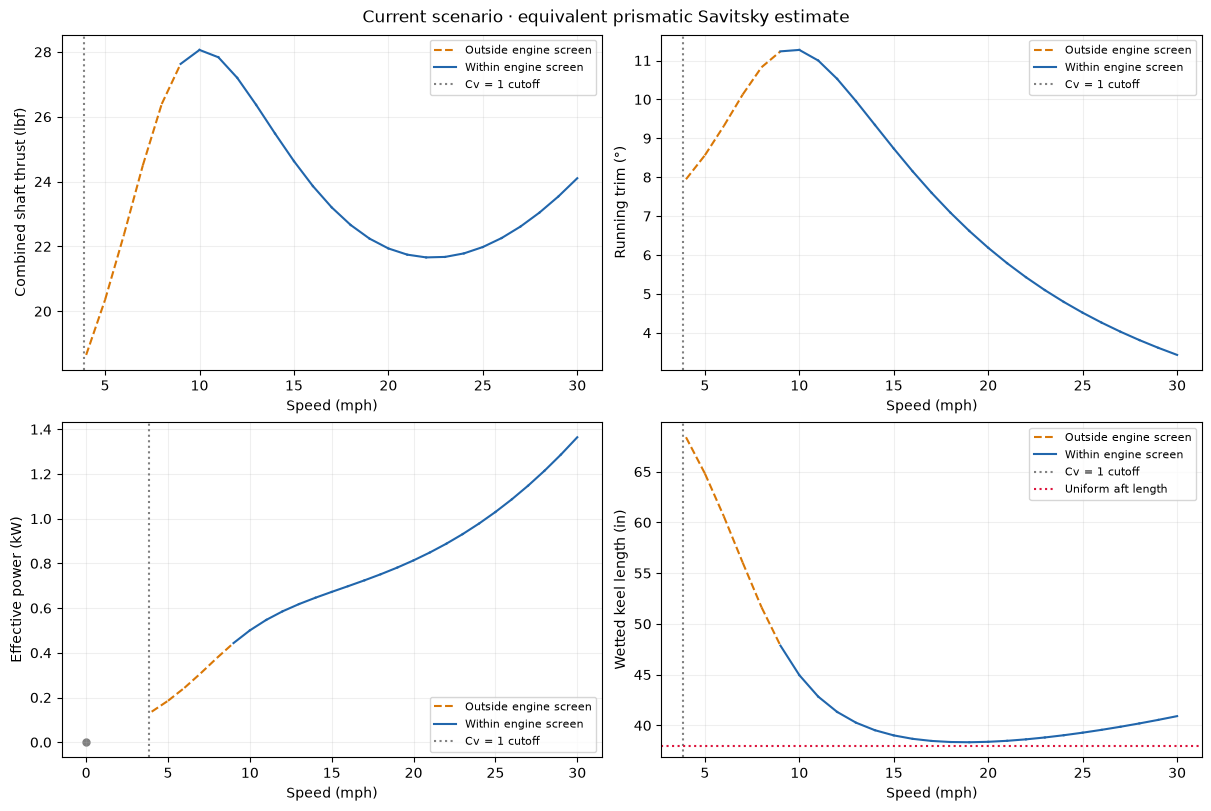

Max normalized force residual: 5.356498963845223e-16
Max normalized moment residual: 2.749177610485355e-15
PASS: force/power identities at 27 solved speeds; shaft-line invariance checked when solved.


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
metrics = [('total_thrust_lbf', 'Combined shaft thrust (lbf)'), ('trim_deg', 'Running trim (°)'),
           ('effective_power_kw', 'Effective power (kW)'), ('keel_wetted_in', 'Wetted keel length (in)')]
cutoff_mph = math.sqrt(G*params['beam_m'])/MPH_TO_M_S
for ax, (key, label) in zip(axes.flat, metrics):
    seen = set()
    for left, right in zip(rows, rows[1:]):
        if 'trim_deg' not in left or 'trim_deg' not in right:
            continue
        outside = any(r['status'] == 'outside_limits' for r in [left, right])
        label_text = 'Outside engine screen' if outside else 'Within engine screen'
        ax.plot([left['speed_mph'], right['speed_mph']], [left[key], right[key]],
                color='#d97706' if outside else '#2166ac', linestyle='--' if outside else '-',
                label=label_text if label_text not in seen else None)
        seen.add(label_text)
    if key == 'effective_power_kw' and any(r['speed_mph'] == 0 for r in rows):
        ax.scatter([0], [0], color='gray', s=25)
    ax.axvline(cutoff_mph, color='gray', linestyle=':', label='Cv = 1 cutoff')
    ax.set(xlabel='Speed (mph)', ylabel=label)
    ax.grid(alpha=0.2)
    if key == 'keel_wetted_in':
        ax.axhline(UNIFORM_AFT_LENGTH_M/IN_TO_M, color='crimson', linestyle=':', label='Uniform aft length')
    ax.legend(fontsize=8)
fig.suptitle('Current scenario · equivalent prismatic Savitsky estimate')
plt.show()

solved = [r for r in rows if 'trim_deg' in r]
for r in solved:
    assert math.isclose(r['resistance_n'], r['pressure_drag_n']+r['friction_drag_n'], abs_tol=1e-9)
    assert math.isclose(r['effective_power_kw'], r['resistance_n']*r['speed_m_s']/1000, abs_tol=1e-12)
    assert abs(r['vertical_residual_n'])/(params['mass_kg']*G) < 1e-6
    assert abs(r['moment_residual_nm'])/(params['mass_kg']*G*params['length_m']) < 1e-6
if solved:
    # Moving the application point along the same shaft line must preserve torque.
    r = solved[-1]
    shifted = {**params, 'thrust_x_m': params['thrust_x_m']+0.1,
               'thrust_height_m': params['thrust_height_m']+0.1*math.tan(math.radians(params['thrust_angle_deg']))}
    moved = forces(shifted, r['speed_m_s'], r['trim_deg'], r['keel_wetted_m'])
    assert math.isclose(moved['thrust_moment_nm'], r['thrust_moment_nm'], abs_tol=1e-9)
    print('Max normalized force residual:', max(abs(r['vertical_residual_n'])/(params['mass_kg']*G) for r in solved))
    print('Max normalized moment residual:', max(abs(r['moment_residual_nm'])/(params['mass_kg']*G*params['length_m']) for r in solved))
print(f'PASS: force/power identities at {len(solved)} solved speeds; shaft-line invariance checked when solved.')


## 9. Compare changes at a chosen speed

Edit `SCENARIOS` to add any supported input overrides. These are applied on top of the current `params`. This is a sensitivity study, not an optimization or an uncertainty bound. Each scenario is solved again; geometry and empirical warnings remain visible.


In [10]:
COMPARE_MPH = DETAIL_MPH
SCENARIOS = {
    'Current inputs': {},
    'Mass +10%': {'mass_kg': params['mass_kg']*1.10},
    'CG forward 1 inch': {'lcg_m': params['lcg_m']+IN_TO_M},
    'Thrust angle 10°': {'thrust_angle_deg': 10.0},
}
comparison = []
for name, changes in SCENARIOS.items():
    r = run_sweep({**params, **changes}, [COMPARE_MPH], UNIFORM_AFT_LENGTH_M, PROPELLER_COUNT)[0]
    comparison.append({'scenario': name, **r})
display(pd.DataFrame(comparison).set_index('scenario').reindex(columns=columns).round(6))


,speed_mph,trim_deg,total_thrust_lbf,per_prop_thrust_lbf,effective_power_kw,keel_wetted_in,status,geometry_warning,warnings
scenario,,,,,,,,,
Current inputs,22.0,5.426987,21.660544,10.830272,0.888012,38.626933,within_screen,Wetting beyond assumed uniform aft section.,[]
Mass +10%,22.0,5.873619,23.983106,11.991553,0.980346,38.208090,within_screen,Wetting beyond assumed uniform aft section.,[]
CG forward 1 inch,22.0,5.260200,21.668908,10.834454,0.889315,40.476417,within_screen,Wetting beyond assumed uniform aft section.,[]
Thrust angle 10°,22.0,5.573716,21.405483,10.702741,0.902061,37.764782,within_screen,,[]


## 10. Optional export

Set `EXPORT_NAME` to a new filename stem (for example `"mass-60kg"`) to save JSON with all inputs, assumptions, intermediate results, and a flat CSV under `outputs/savitsky/notebook-runs/`. Existing names are refused to preserve prior experiments. The historical run is never overwritten. Re-run from section 2 before exporting changed parameters.


In [11]:
EXPORT_NAME = None
if EXPORT_NAME is not None:
    if not isinstance(EXPORT_NAME, str) or not EXPORT_NAME or Path(EXPORT_NAME).name != EXPORT_NAME or EXPORT_NAME in {'.', '..'}:
        raise ValueError('Use a filename stem without directory components.')
    from datetime import datetime, timezone
    out = ROOT / 'outputs/savitsky/notebook-runs'
    targets = [out / f'{EXPORT_NAME}.json', out / f'{EXPORT_NAME}.csv']
    if any(p.exists() for p in targets):
        raise FileExistsError('Choose a new export name; an output already exists.')
    out.mkdir(parents=True, exist_ok=True)
    payload = {'created_utc': datetime.now(timezone.utc).isoformat(),
               'model': 'Python notebook: Savitsky 1964, no flap',
               'inputs': copy.deepcopy(params), 'input_notes': config['input_notes'],
               'uniform_aft_length_m': UNIFORM_AFT_LENGTH_M, 'propeller_count': PROPELLER_COUNT,
               'assumptions': config['assumptions'], 'results': rows}
    targets[0].write_text(json.dumps(payload, indent=2, allow_nan=False)+'\n')
    results.to_csv(targets[1], index=False)
    print('Saved:', *targets, sep='\n')
else:
    print('Export disabled. Set EXPORT_NAME to save a new experiment.')


Export disabled. Set EXPORT_NAME to save a new experiment.


## Sources and interpretation

- [Original local engine](model.js), [calculator documentation](README.md), and [license](NOTICE.txt).
- [OpenPlaning](https://github.com/elcf/python-openplaning), the equation source used by the local engine.
- [Savitsky (1964), Hydrodynamic Design of Planing Hulls](https://onepetro.org/MTSN/article-abstract/1/04/71/172383/Hydrodynamic-Design-of-Planing-Hulls), original empirical method.
- [Unrounded historical data](../../outputs/savitsky/current-hull-2026-10-21/results.json).

The historical engine has a separate published 1976 worked-example regression in `model.test.js`. This workbook verifies the 1964 current-hull port against the saved run and checks equilibrium and force/power identities. It does not repeat that 1976 validation or resolve the non-prismatic hull approximation. The optimizer in `explore.ipynb` is a separate model.
